# 03 · GNN Comparison: GCN, GAT, GraphSAGE

All three models use BERT features of every node and the propagation graph. The architecture follows the official UPFD / PyG example:

`conv → ReLU → graph pooling → concatenate with projected root (news) vector → Linear → ReLU → Linear`

| Setting | Value here | Official UPFD example |
|---|---|---|
| Conv layers | `NUM_LAYERS = 1` | 1 |
| Pooling | `READOUT = "max"` | max |
| Root fusion | `ROOT_FUSION = True` | yes |
| Edges | as stored (parent to child) | made undirected |
| Training | same for all models, early stopping on validation macro-F1 | fixed epochs |

Only the convolution differs between models. Change the settings in section 2 to run other variants (for example `READOUT = "mean"`, `NUM_LAYERS = 2`, `ROOT_FUSION = False`). Results are saved per setting.

Reference: Dou et al., User Preference-aware Fake News Detection (SIGIR 2021), https://github.com/safe-graph/GNN-FakeNews

## 1 · Imports

In [1]:
import sys, os, json, time, platform, warnings, random, logging, gc
from pathlib import Path
import psutil

import numpy as np
import pandas as pd
import scipy
import scipy.sparse as sp
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             roc_curve, confusion_matrix, precision_recall_fscore_support)

try:
    from tqdm.auto import tqdm
except ImportError:
    print("tqdm not installed -> progress bars disabled.  Install with: pip install tqdm")
    def tqdm(iterable=None, **kwargs):
        return iterable

IMPORT_PROBLEMS = []

try:
    import torch
    import torch.nn as nn
    import torch.nn.functional as F
except ImportError as exc:
    torch = nn = F = None
    IMPORT_PROBLEMS.append(("PyTorch", repr(exc)))

try:
    import torch_geometric
    from torch_geometric.data import Data
    from torch_geometric.loader import DataLoader
    from torch_geometric.nn import GCNConv, GATConv, SAGEConv, global_mean_pool, global_max_pool
    from torch_geometric.utils import to_undirected
except Exception as exc:
    torch_geometric = None
    IMPORT_PROBLEMS.append(("PyTorch Geometric (Data, DataLoader, GCNConv, GATConv, SAGEConv, pooling)", repr(exc)))

try:
    from torch_geometric.datasets import UPFD
    PYG_IMPORT_ERROR = None
except Exception as exc:
    UPFD = None
    PYG_IMPORT_ERROR = repr(exc)

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 170)


def rss_mb():
    return psutil.Process().memory_info().rss / 1e6

In [2]:
INSTALL_HELP = "Install PyTorch from https://pytorch.org/get-started/locally/ and then run: pip install torch_geometric tqdm"

versions = {"Python": sys.version.split()[0], "Platform": platform.platform(), "NumPy": np.__version__,
            "Pandas": pd.__version__, "SciPy": scipy.__version__, "scikit-learn": sklearn.__version__,
            "PyTorch": torch.__version__ if torch is not None else "NOT INSTALLED",
            "PyG": torch_geometric.__version__ if torch_geometric is not None else "NOT AVAILABLE"}
for k, v in versions.items():
    print(f"{k:<14}{v}")

if IMPORT_PROBLEMS:
    raise RuntimeError("Missing packages: " + ", ".join(n for n, _ in IMPORT_PROBLEMS) + "\n" + INSTALL_HELP)

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
    print("Device: CUDA ->", torch.cuda.get_device_name(0))
else:
    DEVICE = torch.device("cpu")
    print("Device: CPU")

Python        3.13.13
Platform      Windows-11-10.0.26200-SP0
NumPy         2.4.3
Pandas        2.3.3
SciPy         1.17.1
scikit-learn  1.8.0
PyTorch       2.11.0+cpu
PyG           2.8.1
Device: CPU


## 2 · Configuration

In [3]:
SEED = 42
FEATURE = "bert"
EXPECTED_FEATURE_DIM = 768
DATASETS = ["politifact", "gossipcop"]
DATASET_TITLES = {"politifact": "PolitiFact", "gossipcop": "GossipCop"}
SPLITS = ["train", "val", "test"]


FAKE_CLASS_INDEX = None
if FAKE_CLASS_INDEX is None:
    CLASS_NAMES = {0: "class 0", 1: "class 1"}
else:
    CLASS_NAMES = {FAKE_CLASS_INDEX: "fake", 1 - FAKE_CLASS_INDEX: "real"}
CLASS_COLORS = {0: "#0072B2", 1: "#D55E00"}


def find_project_root(start=None):
    start = Path(start or Path.cwd()).resolve()
    for candidate in [start, *start.parents]:
        if (candidate / "data" / "upfd").is_dir():
            return candidate
    for candidate in [start, *start.parents]:
        if (candidate / "notebooks").is_dir() and (candidate / "README.md").is_file():
            return candidate
    return start.parent if start.name == "notebooks" else start


PROJECT_ROOT = find_project_root()
UPFD_ROOT = PROJECT_ROOT / "data" / "upfd"
RESULTS_DIR = PROJECT_ROOT / "results"
METRICS_DIR = RESULTS_DIR / "metrics"
FIGURES_DIR = RESULTS_DIR / "figures"
LOGS_DIR = RESULTS_DIR / "logs"
CHECKPOINTS_DIR = RESULTS_DIR / "checkpoints"
for _d in (METRICS_DIR, FIGURES_DIR, LOGS_DIR, CHECKPOINTS_DIR):
    _d.mkdir(parents=True, exist_ok=True)

print("Working directory:", Path.cwd())
print("Project root     :", PROJECT_ROOT)
print("UPFD data root   :", UPFD_ROOT, "(found)" if UPFD_ROOT.is_dir() else "(NOT FOUND)")
if not UPFD_ROOT.is_dir():
    raise FileNotFoundError(
        f"Could not find '{UPFD_ROOT}'. Start Jupyter from inside the project folder "
        "(e.g. `cd FakeNews-detection-GNN` then `jupyter lab`) so that data/upfd/ can be located."
    )


SAVED_ARTIFACTS = []


def _json_default(obj):
    if isinstance(obj, (np.integer,)):
        return int(obj)
    if isinstance(obj, (np.floating,)):
        return None if np.isnan(obj) else float(obj)
    if isinstance(obj, np.ndarray):
        return obj.tolist()
    if isinstance(obj, Path):
        return str(obj)
    return str(obj)


def _register(path, kind):
    path = Path(path)
    try:
        shown = str(path.relative_to(PROJECT_ROOT))
    except ValueError:
        shown = str(path)
    SAVED_ARTIFACTS.append({"kind": kind, "path": shown, "size_kB": round(path.stat().st_size / 1024, 1)})


def save_figure(fig, path, dpi=150):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(path, dpi=dpi, bbox_inches="tight")
    _register(path, "figure")
    return path


def save_dataframe(df, path, index=False):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    df.to_csv(path, index=index)
    _register(path, "csv")
    return path


def save_json(obj, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(obj, indent=2, default=_json_default), encoding="utf-8")
    _register(path, "json")
    return path

Working directory: C:\Users\shara\FakeNews-detection-GNN\notebooks
Project root     : C:\Users\shara\FakeNews-detection-GNN
UPFD data root   : C:\Users\shara\FakeNews-detection-GNN\data\upfd (found)


In [4]:
SEEDS = [42, 43, 44, 45, 46]
GNN_MODELS = ["GCN", "GAT", "GraphSAGE"]

EDGE_MODE = "as_stored"
READOUT = "max"
NUM_LAYERS = 1
ROOT_FUSION = True
NUM_WORKERS = 0

CFG = {
    "hidden_dim": 128,
    "dropout": 0.5,
    "lr": 1e-3,
    "weight_decay": 5e-4,
    "max_epochs": 100,
    "patience": 15,
    "gat_heads": 1,
    "gat_attn_dropout": 0.0,
}
BATCH_SIZE = {"politifact": 32, "gossipcop": 64}
EVAL_BATCH_SIZE = {"politifact": 64, "gossipcop": 128}

assert EDGE_MODE in ("as_stored", "undirected")
assert READOUT in ("mean", "max")
assert NUM_LAYERS >= 1
assert CFG["hidden_dim"] % CFG["gat_heads"] == 0

SETTING = f"L{NUM_LAYERS}_{READOUT}_{'root' if ROOT_FUSION else 'noroot'}_{EDGE_MODE}"

GNN_METRICS_DIR = METRICS_DIR / "gnn"
GNN_PRED_DIR = GNN_METRICS_DIR / "predictions"
GNN_FIG_DIR = FIGURES_DIR / "gnn"
GNN_LOG_DIR = LOGS_DIR / "gnn"
GNN_CKPT_DIR = CHECKPOINTS_DIR / "gnn"
for _d in (GNN_METRICS_DIR, GNN_PRED_DIR, GNN_FIG_DIR, GNN_LOG_DIR, GNN_CKPT_DIR):
    _d.mkdir(parents=True, exist_ok=True)


def run_tag(model_name, dataset_key, seed):
    return f"{model_name.lower()}_{dataset_key}_seed{seed}_{SETTING}"


RUN_ID = time.strftime("%Y%m%d_%H%M%S")
LOG_PATH = GNN_LOG_DIR / f"gnn_comparison_{RUN_ID}.log"
logger = logging.getLogger("gnn_comparison")
logger.setLevel(logging.INFO)
logger.handlers.clear()
_fh = logging.FileHandler(LOG_PATH, mode="a", encoding="utf-8")
_fh.setFormatter(logging.Formatter("%(asctime)s | %(levelname)s | %(message)s"))
logger.addHandler(_fh)
logger.info("Notebook 03 started | setting=%s | seeds=%s | cfg=%s | device=%s", SETTING, SEEDS, CFG, DEVICE)


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


print("Setting:", SETTING)
print("Seeds  :", SEEDS)

Setting: L1_max_root_as_stored
Seeds  : [42, 43, 44, 45, 46]


## 3 · Load data and build graphs

In [5]:
REQUIRED_FILES = [
    "A.txt", "graph_labels.npy", "node_graph_id.npy",
    "train_idx.npy", "val_idx.npy", "test_idx.npy",
]
FEATURE_FILE = f"new_{FEATURE}_feature.npz"


def detect_layout(name, root=UPFD_ROOT):
    base = Path(root) / name
    required = REQUIRED_FILES + [FEATURE_FILE]
    problems = []
    for label, directory in (("raw", base / "raw"), ("flat", base)):
        if not directory.is_dir():
            problems.append(f"  - {directory}: directory does not exist")
            continue
        missing = [f for f in required if not (directory / f).is_file()]
        if not missing:
            return label, directory
        problems.append(f"  - {directory}: missing {missing}")
    raise FileNotFoundError(
        f"Could not find a complete UPFD '{name}' dataset under {base}.\n"
        + "\n".join(problems)
        + "\nThe files must be either directly inside that folder or inside its 'raw/' sub-folder."
    )


def load_feature_matrix(path):
    path = Path(path)
    try:
        X = sp.load_npz(path)
        kind = f"scipy.sparse ({X.format})"
    except Exception as sparse_error:
        try:
            with np.load(path, allow_pickle=False) as archive:
                arrays = {k: archive[k] for k in archive.files}
        except Exception as dense_error:
            raise ValueError(
                f"{path.name} is neither a SciPy sparse archive ({sparse_error!r}) "
                f"nor a readable NumPy archive ({dense_error!r})."
            )
        candidates = [k for k, v in arrays.items() if v.ndim == 2]
        if len(candidates) != 1:
            raise ValueError(
                f"{path.name} is not a SciPy sparse archive ({sparse_error!r}) and contains "
                f"{len(candidates)} two-dimensional arrays (keys: {list(arrays)}), so the feature "
                "matrix cannot be identified unambiguously."
            )
        X = sp.csr_matrix(arrays[candidates[0]])
        kind = f"dense array stored under key '{candidates[0]}'"
    return X.tocsr().astype(np.float32, copy=False), kind


def load_upfd_raw(name, load_features=True):
    layout, d = detect_layout(name)

    node_graph_id = np.load(d / "node_graph_id.npy", allow_pickle=False).reshape(-1).astype(np.int64)
    n_nodes = int(node_graph_id.shape[0])

    y_raw = np.load(d / "graph_labels.npy", allow_pickle=False).reshape(-1)
    classes_raw, y = np.unique(y_raw, return_inverse=True)
    y = np.asarray(y, dtype=np.int64).reshape(-1)
    n_graphs = int(y.shape[0])

    if node_graph_id.min() < 0 or node_graph_id.max() >= n_graphs:
        raise ValueError(
            f"[{name}] node_graph_id.npy contains ids in [{node_graph_id.min()}, {node_graph_id.max()}] "
            f"but graph_labels.npy describes {n_graphs} graphs (valid ids: 0..{n_graphs - 1})."
        )
    if np.any(np.diff(node_graph_id) < 0):
        raise ValueError(
            f"[{name}] node_graph_id.npy is not sorted, i.e. the nodes of one graph are not contiguous. "
            "The PyG-style slicing used here (and by PyG itself) would be wrong."
        )
    node_counts = np.bincount(node_graph_id, minlength=n_graphs)
    if np.any(node_counts == 0):
        raise ValueError(f"[{name}] {(node_counts == 0).sum()} graph id(s) own zero nodes.")
    node_slice = np.concatenate([[0], np.cumsum(node_counts)]).astype(np.int64)


    edges_raw = pd.read_csv(d / "A.txt", header=None, sep=",", skipinitialspace=True).to_numpy()
    if edges_raw.ndim != 2 or edges_raw.shape[1] != 2:
        raise ValueError(f"[{name}] A.txt should have exactly two comma-separated columns, got shape {edges_raw.shape}.")
    edges_raw = edges_raw.astype(np.int64)
    if edges_raw.min() < 0 or edges_raw.max() >= n_nodes:
        raise ValueError(
            f"[{name}] A.txt node ids range over [{edges_raw.min()}, {edges_raw.max()}] but there are "
            f"{n_nodes} nodes (valid: 0..{n_nodes - 1}). If the ids start at 1 the file is 1-indexed."
        )
    n_edges_raw = int(len(edges_raw))
    n_self_loops = int((edges_raw[:, 0] == edges_raw[:, 1]).sum())
    edges = np.unique(edges_raw, axis=0)
    n_duplicates = n_edges_raw - int(len(edges))
    key = edges[:, 0] * n_nodes + edges[:, 1]
    rev_key = edges[:, 1] * n_nodes + edges[:, 0]
    n_reciprocal = int((np.isin(rev_key, key) & (edges[:, 0] != edges[:, 1])).sum())

    src_gid = node_graph_id[edges[:, 0]]
    dst_gid = node_graph_id[edges[:, 1]]
    n_cross = int((src_gid != dst_gid).sum())
    if n_cross:
        raise ValueError(f"[{name}] {n_cross} edge(s) connect nodes that belong to different graphs.")
    if np.any(np.diff(src_gid) < 0):
        raise ValueError(f"[{name}] edges are not grouped by graph after sorting; slicing would be wrong.")
    edge_counts = np.bincount(src_gid, minlength=n_graphs)
    edge_slice = np.concatenate([[0], np.cumsum(edge_counts)]).astype(np.int64)


    X, feature_kind = (None, "not loaded")
    if load_features:
        X, feature_kind = load_feature_matrix(d / FEATURE_FILE)
        if X.shape[0] != n_nodes:
            raise ValueError(
                f"[{name}] {FEATURE_FILE} has {X.shape[0]} rows but node_graph_id.npy has {n_nodes} nodes."
            )


    splits = {}
    for s in SPLITS:
        idx = np.load(d / f"{s}_idx.npy", allow_pickle=False).reshape(-1).astype(np.int64)
        if len(idx) and (idx.min() < 0 or idx.max() >= n_graphs):
            raise ValueError(f"[{name}] {s}_idx.npy has indices outside 0..{n_graphs - 1}.")
        splits[s] = idx

    return {
        "name": name, "layout": layout, "dir": d,
        "X": X, "feature_kind": feature_kind,
        "edges": edges, "edge_slice": edge_slice, "node_slice": node_slice,
        "node_graph_id": node_graph_id, "y": y, "y_raw": y_raw, "classes_raw": classes_raw,
        "splits": splits, "n_nodes": n_nodes, "n_graphs": n_graphs,
        "audit": {
            "edges_in_A_txt": n_edges_raw, "unique_edges_after_coalesce": int(len(edges)),
            "duplicate_edges": n_duplicates, "self_loops": n_self_loops,
            "reciprocal_directed_edges": n_reciprocal, "cross_graph_edges": n_cross,
            "min_node_id": int(edges_raw.min()), "max_node_id": int(edges_raw.max()),
        },
    }


def graph_num_nodes(raw, i):
    return int(raw["node_slice"][i + 1] - raw["node_slice"][i])


def local_edges(raw, i):
    return raw["edges"][raw["edge_slice"][i]:raw["edge_slice"][i + 1]] - raw["node_slice"][i]


def root_features(raw, graph_indices):
    rows = raw["node_slice"][np.asarray(graph_indices, dtype=np.int64)]
    return raw["X"][rows].toarray()


def check_splits(raw):
    G = raw["n_graphs"]
    sets = {s: set(raw["splits"][s].tolist()) for s in SPLITS}
    rows = []
    for s in SPLITS:
        idx = raw["splits"][s]
        rows.append({
            "split": s, "n_indices": len(idx), "n_unique": len(sets[s]),
            "duplicates": len(idx) - len(sets[s]),
            "min_index": int(idx.min()) if len(idx) else None,
            "max_index": int(idx.max()) if len(idx) else None,
            "out_of_range": int(((idx < 0) | (idx >= G)).sum()),
        })
    overlaps = {f"{a} & {b}": len(sets[a] & sets[b]) for a, b in [("train", "val"), ("train", "test"), ("val", "test")]}
    union = set().union(*sets.values())
    coverage = {"graphs_in_union": len(union), "total_graphs": G, "graphs_in_no_split": G - len(union)}
    return pd.DataFrame(rows), overlaps, coverage


def root_convention_check(raw):
    rows = []
    for i in range(raw["n_graphs"]):
        n = graph_num_nodes(raw, i)
        e = local_edges(raw, i)
        indeg = np.bincount(e[:, 1], minlength=n)
        outdeg = np.bincount(e[:, 0], minlength=n)
        rows.append((i, n, len(e), int(indeg[0]), int(outdeg[0]), int((indeg == 0).sum()), int((outdeg == 0).sum())))
    df = pd.DataFrame(rows, columns=["graph_idx", "num_nodes", "num_edges", "node0_in_degree",
                                     "node0_out_degree", "n_sources", "n_sinks"])
    df["node0_unique_source"] = (df["node0_in_degree"] == 0) & (df["n_sources"] == 1)
    df["node0_unique_sink"] = (df["node0_out_degree"] == 0) & (df["n_sinks"] == 1)
    return df


def summarize_root_check(df, name):
    frac_source = float(df["node0_unique_source"].mean())
    frac_sink = float(df["node0_unique_sink"].mean())
    direction = ("edges point from node 0 (root) outwards: parent -> child"
                 if frac_source >= frac_sink else
                 "edges point towards node 0 (root): child -> parent")
    summary = {
        "dataset": name, "graphs": len(df),
        "node0_is_unique_source": f"{int(df['node0_unique_source'].sum())} / {len(df)}",
        "node0_is_unique_sink": f"{int(df['node0_unique_sink'].sum())} / {len(df)}",
        "edge_direction_inferred": direction,
        "graphs_with_edges_eq_nodes_minus_1": f"{int((df['num_edges'] == df['num_nodes'] - 1).sum())} / {len(df)}",
    }
    if max(frac_source, frac_sink) < 0.95:
        raise RuntimeError(
            f"[{name}] local node 0 is the unique root in only {max(frac_source, frac_sink):.1%} of graphs. "
            "The assumption 'graph.x[0] is the news node' is NOT supported by this data; stop and investigate."
        )
    if max(frac_source, frac_sink) < 1.0:
        bad = df.loc[~(df["node0_unique_source"] if frac_source >= frac_sink else df["node0_unique_sink"]), "graph_idx"]
        warnings.warn(f"[{name}] root convention violated in graphs {bad.head(10).tolist()} (showing up to 10).")
    return summary

In [6]:
RAW, LOAD_TIME = {}, {}
for name in DATASETS:
    t0 = time.perf_counter()
    RAW[name] = load_upfd_raw(name)
    LOAD_TIME[name] = time.perf_counter() - t0
    r = RAW[name]
    print(f"{DATASET_TITLES[name]:<11} loaded in {LOAD_TIME[name]:5.1f}s | graphs={r['n_graphs']:,} | nodes={r['n_nodes']:,} | "
          f"edges={len(r['edges']):,} | features {r['X'].shape}")
    assert len(r["classes_raw"]) == 2
    assert r["X"].shape[1] == EXPECTED_FEATURE_DIM
print(f"CPU memory after loading: {rss_mb():.0f} MB")

PolitiFact  loaded in   4.2s | graphs=314 | nodes=41,054 | edges=40,740 | features (41054, 768)
GossipCop   loaded in  32.6s | graphs=5,464 | nodes=314,262 | edges=308,798 | features (314262, 768)
CPU memory after loading: 2690 MB


In [7]:
def graph_to_data(raw, i, edge_mode=EDGE_MODE):
    a, b = int(raw["node_slice"][i]), int(raw["node_slice"][i + 1])
    x = torch.from_numpy(raw["X"][a:b].toarray())
    edge_index = torch.from_numpy(np.ascontiguousarray(local_edges(raw, i).T))
    if edge_mode == "undirected":
        edge_index = to_undirected(edge_index, num_nodes=x.shape[0])
    return Data(x=x, edge_index=edge_index, y=torch.tensor([int(raw["y"][i])], dtype=torch.long),
                graph_idx=torch.tensor([int(i)], dtype=torch.long))


GRAPHS, BUILD_TIME = {}, {}
for name in DATASETS:
    raw = RAW[name]
    t0 = time.perf_counter()
    GRAPHS[name] = {s: [graph_to_data(raw, int(i)) for i in tqdm(raw["splits"][s], desc=f"{name}/{s}", leave=False)] for s in SPLITS}
    BUILD_TIME[name] = time.perf_counter() - t0
    print(f"{DATASET_TITLES[name]:<11}: " + " | ".join(f"{s}={len(GRAPHS[name][s])}" for s in SPLITS) + f" graphs built in {BUILD_TIME[name]:.1f}s")
print(f"CPU memory after building graphs: {rss_mb():.0f} MB")

politifact/train:   0%|          | 0/62 [00:00<?, ?it/s]

politifact/val:   0%|          | 0/31 [00:00<?, ?it/s]

politifact/test:   0%|          | 0/221 [00:00<?, ?it/s]

PolitiFact : train=62 | val=31 | test=221 graphs built in 1.0s


gossipcop/train:   0%|          | 0/1092 [00:00<?, ?it/s]

gossipcop/val:   0%|          | 0/546 [00:00<?, ?it/s]

gossipcop/test:   0%|          | 0/3826 [00:00<?, ?it/s]

GossipCop  : train=1092 | val=546 | test=3826 graphs built in 6.8s
CPU memory after building graphs: 3811 MB


## 4 · Data checks

In [8]:
for name in DATASETS:
    raw = RAW[name]
    split_df, overlaps, coverage = check_splits(raw)
    print(f"\n=== {DATASET_TITLES[name]} ===")
    display(split_df.set_index("split"))
    print("Overlaps:", overlaps, "| coverage:", coverage)
    assert all(v == 0 for v in overlaps.values()), f"{name}: splits overlap -> data leakage"
    assert split_df["duplicates"].sum() == 0 and split_df["out_of_range"].sum() == 0
    ids = {s: {int(g.graph_idx) for g in GRAPHS[name][s]} for s in SPLITS}
    assert not (ids["train"] & ids["val"]) and not (ids["train"] & ids["test"]) and not (ids["val"] & ids["test"])
print("\nSplit checks passed (official indices, disjoint, in range).")


=== PolitiFact ===


,n_indices,n_unique,duplicates,min_index,max_index,out_of_range
split,,,,,,
train,62,62,0,1,313,0
val,31,31,0,8,302,0
test,221,221,0,0,312,0


Overlaps: {'train & val': 0, 'train & test': 0, 'val & test': 0} | coverage: {'graphs_in_union': 314, 'total_graphs': 314, 'graphs_in_no_split': 0}

=== GossipCop ===


,n_indices,n_unique,duplicates,min_index,max_index,out_of_range
split,,,,,,
train,1092,1092,0,1,5456,0
val,546,546,0,21,5454,0
test,3826,3826,0,0,5463,0


Overlaps: {'train & val': 0, 'train & test': 0, 'val & test': 0} | coverage: {'graphs_in_union': 5464, 'total_graphs': 5464, 'graphs_in_no_split': 0}

Split checks passed (official indices, disjoint, in range).


In [9]:
rng = np.random.default_rng(SEED)
for name in DATASETS:
    raw = RAW[name]
    for s in SPLITS:
        lst, idx = GRAPHS[name][s], raw["splits"][s]
        assert [int(g.graph_idx) for g in lst] == idx.tolist(), "graph order differs from the official split order"
        assert all(int(g.y) == int(raw["y"][int(g.graph_idx)]) for g in lst), "label mismatch"
        assert all(g.x.shape[1] == EXPECTED_FEATURE_DIM and g.x.dtype == torch.float32 for g in lst)
        assert all(g.x.shape[0] == graph_num_nodes(raw, int(g.graph_idx)) for g in lst), "node count mismatch"
        roots = torch.stack([g.x[0] for g in lst]).numpy()
        assert np.array_equal(roots, root_features(raw, idx)), "feature row of local node 0 differs from raw file"
        for k in rng.choice(len(lst), size=min(100, len(lst)), replace=False):
            g, gi = lst[int(k)], int(lst[int(k)].graph_idx)
            assert np.array_equal(g.x.numpy(), raw["X"][raw["node_slice"][gi]:raw["node_slice"][gi + 1]].toarray())
            if EDGE_MODE == "as_stored":
                assert np.array_equal(g.edge_index.t().numpy(), local_edges(raw, gi)), "edges differ from A.txt (after coalesce)"
            ei = g.edge_index
            assert ei.numel() == 0 or (int(ei.min()) >= 0 and int(ei.max()) < g.x.shape[0]), "edge points outside its own graph"
    print(f"{DATASET_TITLES[name]:<11}: Data objects match the raw files (order, labels, features, edges).")

PolitiFact : Data objects match the raw files (order, labels, features, edges).
GossipCop  : Data objects match the raw files (order, labels, features, edges).


In [10]:
ROOT_CHECK = {name: root_convention_check(RAW[name]) for name in DATASETS}
display(pd.DataFrame([summarize_root_check(ROOT_CHECK[n], DATASET_TITLES[n]) for n in DATASETS]).set_index("dataset").T)

EDGE_DIRECTION = {}
for name in DATASETS:
    rc = ROOT_CHECK[name]
    EDGE_DIRECTION[name] = "parent_to_child" if rc["node0_unique_source"].mean() >= rc["node0_unique_sink"].mean() else "child_to_parent"
print("Inferred edge direction:", EDGE_DIRECTION)

if EDGE_MODE == "as_stored":
    for name in DATASETS:
        if EDGE_DIRECTION[name] == "parent_to_child":
            print(f"[{DATASET_TITLES[name]}] PyG sends messages source -> target, i.e. along parent -> child. A node therefore receives from its parent "
                  "(and, after layer 2, its grandparent). The root has no incoming edges: it never receives messages from users and keeps only its own "
                  "vector. User-node vectors absorb the news vector from above; the mean readout averages root and user vectors.")
        else:
            print(f"[{DATASET_TITLES[name]}] edges point child -> parent: messages flow from users UP to the root, which collects information from its whole subtree.")
else:
    print("EDGE_MODE='undirected': reverse edges were added, so messages flow both ways (this is NOT the stored convention).")

dataset,PolitiFact,GossipCop
graphs,314,5464
node0_is_unique_source,314 / 314,5464 / 5464
node0_is_unique_sink,0 / 314,0 / 5464
edge_direction_inferred,edges point from node 0 (root) outwards: paren...,edges point from node 0 (root) outwards: paren...
graphs_with_edges_eq_nodes_minus_1,314 / 314,5464 / 5464


Inferred edge direction: {'politifact': 'parent_to_child', 'gossipcop': 'parent_to_child'}
[PolitiFact] PyG sends messages source -> target, i.e. along parent -> child. A node therefore receives from its parent (and, after layer 2, its grandparent). The root has no incoming edges: it never receives messages from users and keeps only its own vector. User-node vectors absorb the news vector from above; the mean readout averages root and user vectors.
[GossipCop] PyG sends messages source -> target, i.e. along parent -> child. A node therefore receives from its parent (and, after layer 2, its grandparent). The root has no incoming edges: it never receives messages from users and keeps only its own vector. User-node vectors absorb the news vector from above; the mean readout averages root and user vectors.


In [11]:
rows = []
for name in DATASETS:
    r = RAW[name]
    counts = {s: np.bincount(r["y"][r["splits"][s]], minlength=2) for s in SPLITS}
    for c in (0, 1):
        rows.append({"dataset": DATASET_TITLES[name], "raw_label_value": r["classes_raw"][c].item(), "class_index": c,
                     "name_used": CLASS_NAMES[c], **{f"{s} graphs": int(counts[s][c]) for s in SPLITS}})
display(pd.DataFrame(rows))
print("Positive class for ROC-AUC (probability column used):", "class index 1" if FAKE_CLASS_INDEX is None else f"class index 1 (fake = class {FAKE_CLASS_INDEX})")
if FAKE_CLASS_INDEX is None:
    print("LABEL SEMANTICS UNVERIFIED -> classes reported as class 0 / class 1.")

,dataset,raw_label_value,class_index,name_used,train graphs,val graphs,test graphs
0,PolitiFact,0.0,0,class 0,36,13,108
1,PolitiFact,1.0,1,class 1,26,18,113
2,GossipCop,0.0,0,class 0,557,265,1910
3,GossipCop,1.0,1,class 1,535,281,1916


Positive class for ROC-AUC (probability column used): class index 1
LABEL SEMANTICS UNVERIFIED -> classes reported as class 0 / class 1.


In [12]:
def check_batching(graphs):
    loader = DataLoader(graphs, batch_size=len(graphs), shuffle=False, num_workers=0)
    batch = next(iter(loader))
    src, dst = batch.edge_index
    assert bool((batch.batch[src] == batch.batch[dst]).all()), "an edge connects two different graphs!"
    assert batch.num_graphs == len(graphs) and batch.ptr.numel() == len(graphs) + 1
    assert batch.y.shape == (len(graphs),) and batch.graph_idx.shape == (len(graphs),)
    assert batch.x.shape == (sum(g.x.shape[0] for g in graphs), EXPECTED_FEATURE_DIM)
    for k, g in enumerate(graphs):
        lo, hi = int(batch.ptr[k]), int(batch.ptr[k + 1])
        assert torch.equal(batch.x[lo:hi], g.x), "node features were mixed up"
        mask = batch.batch[src] == k
        assert torch.equal(batch.edge_index[:, mask] - lo, g.edge_index), "edges were mixed up"
        assert int(batch.y[k]) == int(g.y)
    return batch


for name in DATASETS:
    b = check_batching(GRAPHS[name]["train"][:8])
    print(f"{DATASET_TITLES[name]:<11}: batch of {b.num_graphs} graphs -> x {tuple(b.x.shape)}, edge_index {tuple(b.edge_index.shape)}, "
          f"y {tuple(b.y.shape)}, batch vector {tuple(b.batch.shape)}; graphs stay separate.")

PolitiFact : batch of 8 graphs -> x (1491, 768), edge_index (2, 1483), y (8,), batch vector (1491,); graphs stay separate.
GossipCop  : batch of 8 graphs -> x (539, 768), edge_index (2, 531), y (8,), batch vector (539,); graphs stay separate.


In [13]:
for name in DATASETS:
    RAW[name]["X"] = None
gc.collect()
print(f"CPU memory after releasing raw features: {rss_mb():.0f} MB")

COST = pd.DataFrame([{"dataset": DATASET_TITLES[n], "load_time_s": round(LOAD_TIME[n], 2), "graph_build_time_s": round(BUILD_TIME[n], 2),
                      "nodes": RAW[n]["n_nodes"], "graphs": RAW[n]["n_graphs"]} for n in DATASETS])
save_dataframe(COST, GNN_METRICS_DIR / "data_cost.csv")
display(COST)

CPU memory after releasing raw features: 1654 MB


,dataset,load_time_s,graph_build_time_s,nodes,graphs
0,PolitiFact,4.25,0.96,41054,314
1,GossipCop,32.60,6.77,314262,5464


## 5 · Model and training code

In [14]:
def compute_metrics(y_true, y_pred, y_score):
    y_true, y_pred, y_score = np.asarray(y_true), np.asarray(y_pred), np.asarray(y_score)
    out = {
        "n": int(len(y_true)),
        "accuracy": accuracy_score(y_true, y_pred),
        "precision_macro": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "recall_macro": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "f1_macro": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "roc_auc": roc_auc_score(y_true, y_score) if len(np.unique(y_true)) == 2 else np.nan,
    }
    p, r, f, s = precision_recall_fscore_support(y_true, y_pred, labels=[0, 1], zero_division=0)
    for c in (0, 1):
        out[f"precision_class{c}"], out[f"recall_class{c}"], out[f"f1_class{c}"], out[f"support_class{c}"] = p[c], r[c], f[c], int(s[c])
    if FAKE_CLASS_INDEX is not None:
        real = 1 - FAKE_CLASS_INDEX
        out["precision_fake"], out["recall_fake"] = p[FAKE_CLASS_INDEX], r[FAKE_CLASS_INDEX]
        out["precision_real"], out["recall_real"] = p[real], r[real]
    return out


MODEL_COLORS = {"GCN": "#0072B2", "GAT": "#D55E00", "GraphSAGE": "#009E73"}


def plot_confusion_ax(ax, y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    names = [CLASS_NAMES[0], CLASS_NAMES[1]]
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, xticklabels=names, yticklabels=names, ax=ax)
    ax.set_title(title); ax.set_xlabel("predicted"); ax.set_ylabel("true")
    return cm


def plot_run_figures(model_name, ds, seed, history, best_epoch, y_true, y_pred, y_score, tag):
    title = f"{DATASET_TITLES[ds]} - {model_name} (seed {seed})"

    fig, ax = plt.subplots(figsize=(6, 4))
    ax.plot(history["epoch"], history["train_loss"], label="training loss (eval mode)")
    ax.plot(history["epoch"], history["train_loss_running"], label="training loss (running, dropout on)", ls=":", alpha=0.8)
    ax.plot(history["epoch"], history["val_loss"], label="validation loss")
    ax.axvline(best_epoch, color="grey", ls="--", lw=1, label=f"selected epoch {best_epoch}")
    ax.set_xlabel("epoch"); ax.set_ylabel("cross-entropy"); ax.set_title(f"{title}: loss"); ax.legend(fontsize=8)
    plt.tight_layout(); save_figure(fig, GNN_FIG_DIR / f"{tag}_loss_curves.png"); plt.show()

    fig, ax = plt.subplots(figsize=(6, 4))
    ax.plot(history["epoch"], history["val_f1_macro"], label="validation macro-F1")
    ax.plot(history["epoch"], history["val_acc"], label="validation accuracy")
    ax.plot(history["epoch"], history["val_roc_auc"], label="validation ROC-AUC")
    ax.plot(history["epoch"], history["train_acc"], label="training accuracy", ls=":")
    ax.axvline(best_epoch, color="grey", ls="--", lw=1)
    ax.set_ylim(0, 1.02); ax.set_xlabel("epoch"); ax.set_title(f"{title}: validation performance"); ax.legend(fontsize=8)
    plt.tight_layout(); save_figure(fig, GNN_FIG_DIR / f"{tag}_validation_performance.png"); plt.show()

    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    plot_confusion_ax(axes[0], y_true, y_pred, f"{title}: test confusion matrix")
    fpr, tpr, _ = roc_curve(y_true, y_score)
    auc = roc_auc_score(y_true, y_score) if len(np.unique(y_true)) == 2 else np.nan
    axes[1].plot(fpr, tpr, lw=2, label=f"AUC = {auc:.3f}"); axes[1].plot([0, 1], [0, 1], "k--", lw=1, label="chance")
    axes[1].set_xlabel("false-positive rate (class 1 = positive)"); axes[1].set_ylabel("true-positive rate"); axes[1].set_title("test ROC"); axes[1].legend(loc="lower right")
    plt.tight_layout(); save_figure(fig, GNN_FIG_DIR / f"{tag}_confusion_and_roc.png"); plt.show()


def append_run_metrics(rows, csv_path):
    """Append metric rows without relying on pandas merge-key dtypes.

    Older result CSVs may contain blank or numeric values in `setting`
    (for example, an all-NaN column is read as float64), while the current
    notebook writes a string setting. Comparing normalized key tuples avoids
    the float64/object merge error and preserves older rows.
    """
    new = pd.DataFrame(rows)
    key = ["dataset", "model", "seed", "split", "setting"]

    def normalise_key_value(column, value):
        if pd.isna(value):
            return "<MISSING>"
        if column == "seed":
            # CSV files may infer seed as 42.0 when older rows contain blanks.
            try:
                return str(int(float(value)))
            except (TypeError, ValueError, OverflowError):
                pass
        return str(value).strip()

    def row_key(row):
        return tuple(normalise_key_value(col, row[col]) for col in key)

    if csv_path.is_file():
        old = pd.read_csv(csv_path)
        for column in key:
            if column not in old.columns:
                old[column] = pd.NA

        existing_keys = {row_key(row) for _, row in old.iterrows()}
        keep_indices = []
        for idx, row in new.iterrows():
            current_key = row_key(row)
            if current_key not in existing_keys:
                keep_indices.append(idx)
                existing_keys.add(current_key)

        new_to_append = new.loc[keep_indices]
        combined = pd.concat([old, new_to_append], ignore_index=True, sort=False)
    else:
        combined = new.drop_duplicates(subset=key, keep="last")

    save_dataframe(combined, csv_path)
    return combined


def save_run_outputs(model_name, ds, seed, history, pred_df, metric_rows, meta):
    tag = run_tag(model_name, ds, seed)
    save_dataframe(history, GNN_LOG_DIR / f"{tag}_history.csv")
    save_dataframe(pred_df, GNN_PRED_DIR / f"{tag}_predictions.csv")
    append_run_metrics(metric_rows, GNN_METRICS_DIR / "gnn_metrics.csv")
    save_json(meta, GNN_METRICS_DIR / f"{tag}_metadata.json")
    return tag

In [15]:
READOUTS = {"mean": global_mean_pool, "max": global_max_pool}


class GraphClassifier(nn.Module):
    def __init__(self, convs, in_dim, hidden_dim, dropout, readout, root_fusion, stats_dim=0, n_classes=2):
        super().__init__()
        self.convs = nn.ModuleList(convs)
        self.dropout = dropout
        self.readout = READOUTS[readout]
        self.root_fusion = root_fusion
        self.stats_dim = stats_dim
        fused_dim = hidden_dim
        if root_fusion:
            self.root_lin = nn.Linear(in_dim, hidden_dim)
            fused_dim += hidden_dim
        if stats_dim:
            self.stats_lin = nn.Linear(stats_dim, hidden_dim)
            fused_dim += hidden_dim
        self.fuse = nn.Linear(fused_dim, hidden_dim) if fused_dim != hidden_dim else None
        self.out = nn.Linear(hidden_dim, n_classes)

    def forward(self, x, edge_index, batch, ptr, stats=None):
        h = x
        for k, conv in enumerate(self.convs):
            h = F.relu(conv(h, edge_index))
            if k < len(self.convs) - 1:
                h = F.dropout(h, p=self.dropout, training=self.training)
        g = self.readout(h, batch)
        if self.fuse is not None:
            parts = [g]
            if self.root_fusion:
                parts.append(F.relu(self.root_lin(x[ptr[:-1]])))
            if self.stats_dim:
                parts.append(F.relu(self.stats_lin(stats)))
            g = F.relu(self.fuse(torch.cat(parts, dim=1)))
        g = F.dropout(g, p=self.dropout, training=self.training)
        return self.out(g)


def make_convs(kind, in_dim):
    hidden, heads = CFG["hidden_dim"], CFG["gat_heads"]
    dims = [in_dim] + [hidden] * NUM_LAYERS
    convs = []
    for a, b in zip(dims[:-1], dims[1:]):
        if kind == "GCN":
            convs.append(GCNConv(a, b))
        elif kind == "GAT":
            convs.append(GATConv(a, b // heads, heads=heads, concat=True, dropout=CFG["gat_attn_dropout"]))
        else:
            convs.append(SAGEConv(a, b, aggr="mean"))
    return convs


def build_model(kind, in_dim, stats_dim=0):
    return GraphClassifier(make_convs(kind, in_dim), in_dim, CFG["hidden_dim"], CFG["dropout"], READOUT, ROOT_FUSION, stats_dim)


MODEL_BUILDERS = {m: (lambda in_dim, m=m: build_model(m, in_dim)) for m in GNN_MODELS}


def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


def make_loaders(ds, seed):
    gen = torch.Generator()
    gen.manual_seed(seed)
    common = {"num_workers": NUM_WORKERS}
    return {
        "train": DataLoader(GRAPHS[ds]["train"], batch_size=BATCH_SIZE[ds], shuffle=True, generator=gen, **common),
        "train_eval": DataLoader(GRAPHS[ds]["train"], batch_size=EVAL_BATCH_SIZE[ds], shuffle=False, **common),
        "val": DataLoader(GRAPHS[ds]["val"], batch_size=EVAL_BATCH_SIZE[ds], shuffle=False, **common),
        "test": DataLoader(GRAPHS[ds]["test"], batch_size=EVAL_BATCH_SIZE[ds], shuffle=False, **common),
    }


def evaluate(model, loader):
    model.eval()
    total, n = 0.0, 0
    ys, preds, scores, gids = [], [], [], []
    with torch.no_grad():
        for batch in loader:
            batch = batch.to(DEVICE)
            logits = model(batch.x, batch.edge_index, batch.batch, batch.ptr)
            total += F.cross_entropy(logits, batch.y, reduction="sum").item()
            n += batch.num_graphs
            proba = torch.softmax(logits, dim=1)
            ys.append(batch.y.cpu().numpy()); preds.append(logits.argmax(dim=1).cpu().numpy())
            scores.append(proba[:, 1].cpu().numpy()); gids.append(batch.graph_idx.cpu().numpy())
    return {"loss": total / n, "y_true": np.concatenate(ys), "y_pred": np.concatenate(preds),
            "y_score": np.concatenate(scores), "graph_idx": np.concatenate(gids)}


def run_experiment(model_name, ds, seed):
    set_seed(seed)
    loaders = make_loaders(ds, seed)
    in_dim = GRAPHS[ds]["train"][0].x.shape[1]
    model = MODEL_BUILDERS[model_name](in_dim).to(DEVICE)
    n_params = count_parameters(model)
    optimizer = torch.optim.Adam(model.parameters(), lr=CFG["lr"], weight_decay=CFG["weight_decay"])
    if DEVICE.type == "cuda":
        torch.cuda.reset_peak_memory_stats()

    best = {"f1": -1.0, "loss": np.inf, "epoch": 0, "state": None}
    bad_epochs, history = 0, []
    t_start = time.perf_counter()
    try:
        for epoch in range(1, CFG["max_epochs"] + 1):
            t_ep = time.perf_counter()
            model.train()
            running, seen = 0.0, 0
            for batch in loaders["train"]:
                batch = batch.to(DEVICE)
                optimizer.zero_grad(set_to_none=True)
                logits = model(batch.x, batch.edge_index, batch.batch, batch.ptr)
                loss = F.cross_entropy(logits, batch.y)
                loss.backward()
                optimizer.step()
                running += loss.item() * batch.num_graphs
                seen += batch.num_graphs
            tr, va = evaluate(model, loaders["train_eval"]), evaluate(model, loaders["val"])
            tr_m = compute_metrics(tr["y_true"], tr["y_pred"], tr["y_score"])
            va_m = compute_metrics(va["y_true"], va["y_pred"], va["y_score"])
            history.append({"epoch": epoch, "train_loss_running": running / seen, "train_loss": tr["loss"], "train_acc": tr_m["accuracy"],
                            "val_loss": va["loss"], "val_acc": va_m["accuracy"], "val_f1_macro": va_m["f1_macro"],
                            "val_roc_auc": va_m["roc_auc"], "epoch_seconds": time.perf_counter() - t_ep})
            better = (va_m["f1_macro"] > best["f1"] + 1e-12) or (abs(va_m["f1_macro"] - best["f1"]) <= 1e-12 and va["loss"] < best["loss"])
            if better:
                best.update(f1=va_m["f1_macro"], loss=va["loss"], epoch=epoch, state={k: v.detach().cpu().clone() for k, v in model.state_dict().items()})
                bad_epochs = 0
            else:
                bad_epochs += 1
                if bad_epochs >= CFG["patience"]:
                    break
    except RuntimeError as exc:
        if "out of memory" in str(exc).lower():
            if DEVICE.type == "cuda":
                torch.cuda.empty_cache()
            raise RuntimeError(f"CUDA out of memory for {model_name} on {ds}. Lower BATCH_SIZE and EVAL_BATCH_SIZE and restart the kernel.") from exc
        raise
    train_time = time.perf_counter() - t_start

    model.load_state_dict(best["state"])
    va = evaluate(model, loaders["val"])
    te = evaluate(model, loaders["test"])
    history = pd.DataFrame(history)
    best_row = history[history["epoch"] == best["epoch"]].iloc[0]

    rows = []
    for split, res in (("val", va), ("test", te)):
        rows.append({"dataset": DATASET_TITLES[ds], "dataset_key": ds, "model": model_name, "seed": seed, "split": split,
                     "setting": SETTING, "edge_mode": EDGE_MODE, "readout": READOUT, "layers": NUM_LAYERS, "root_fusion": ROOT_FUSION,
                     **compute_metrics(res["y_true"], res["y_pred"], res["y_score"])})
    pred_df = pd.concat([pd.DataFrame({"split": s, "graph_idx": r["graph_idx"], "y_true": r["y_true"], "y_pred": r["y_pred"], "p_class1": r["y_score"]})
                         for s, r in (("val", va), ("test", te))], ignore_index=True)
    tag = run_tag(model_name, ds, seed)
    ckpt = GNN_CKPT_DIR / f"{tag}.pt"
    torch.save({"state_dict": best["state"], "model": model_name, "in_dim": in_dim, "cfg": CFG, "setting": SETTING,
                "seed": seed, "dataset": ds, "best_epoch": best["epoch"]}, ckpt)
    _register(ckpt, "checkpoint")

    meta = {"dataset": DATASET_TITLES[ds], "dataset_key": ds, "model": model_name, "seed": seed, "setting": SETTING,
            "edge_mode": EDGE_MODE, "readout": READOUT, "layers": NUM_LAYERS, "root_fusion": ROOT_FUSION, "cfg": CFG,
            "batch_size": BATCH_SIZE[ds], "n_params": n_params, "device": str(DEVICE),
            "best_epoch": best["epoch"], "epochs_run": int(len(history)), "train_time_s": round(train_time, 2),
            "peak_gpu_mb": round(torch.cuda.max_memory_allocated() / 1e6, 1) if DEVICE.type == "cuda" else None,
            "cpu_rss_mb": round(rss_mb(), 1),
            "train_loss_at_best": float(best_row["train_loss"]), "val_loss_at_best": float(best_row["val_loss"]),
            "train_acc_at_best": float(best_row["train_acc"]), "val_acc_at_best": float(best_row["val_acc"]),
            "val_f1_at_best": float(best_row["val_f1_macro"]), "run_id": RUN_ID}
    save_run_outputs(model_name, ds, seed, history, pred_df, rows, meta)
    if seed == SEEDS[0]:
        plot_run_figures(model_name, ds, seed, history, best["epoch"], te["y_true"], te["y_pred"], te["y_score"], tag)
    t = rows[1]
    print(f"{model_name:<10} {DATASET_TITLES[ds]:<11} seed {seed} | best epoch {best['epoch']:>3}/{len(history)} | "
          f"test acc {t['accuracy']:.3f} macro-F1 {t['f1_macro']:.3f} | {train_time:.0f}s")
    logger.info("%s | %s | seed=%d | best_epoch=%d | time=%.1fs | test_f1=%.4f", model_name, ds, seed, best["epoch"], train_time, t["f1_macro"])
    return rows


show_cols = ["dataset", "model", "seed", "split", "n", "accuracy", "precision_macro", "recall_macro", "f1_macro", "roc_auc"]
GNN_ROWS = []


def run_model(model_name):
    for seed in SEEDS:
        for ds in DATASETS:
            GNN_ROWS.extend(run_experiment(model_name, ds, seed))
    t = pd.DataFrame([r for r in GNN_ROWS if r["model"] == model_name and r["split"] == "test"])
    display(t.groupby("dataset")[["accuracy", "f1_macro", "roc_auc"]].agg(["mean", "std"]).round(4))

In [16]:
for m in GNN_MODELS:
    mdl = MODEL_BUILDERS[m](EXPECTED_FEATURE_DIM).to(DEVICE).eval()
    batch = next(iter(DataLoader(GRAPHS["politifact"]["train"][:4], batch_size=4))).to(DEVICE)
    with torch.no_grad():
        logits = mdl(batch.x, batch.edge_index, batch.batch, batch.ptr)
    assert logits.shape == (batch.num_graphs, 2)
    print(f"{m:<10} {type(mdl.convs[0]).__name__:<9} layers={len(mdl.convs)} parameters={count_parameters(mdl):,}")
print(MODEL_BUILDERS["GraphSAGE"](EXPECTED_FEATURE_DIM))

GCN        GCNConv   layers=1 parameters=230,018
GAT        GATConv   layers=1 parameters=230,274
GraphSAGE  SAGEConv  layers=1 parameters=328,322
GraphClassifier(
  (convs): ModuleList(
    (0): SAGEConv(768, 128, aggr=mean)
  )
  (root_lin): Linear(in_features=768, out_features=128, bias=True)
  (fuse): Linear(in_features=256, out_features=128, bias=True)
  (out): Linear(in_features=128, out_features=2, bias=True)
)


## 6 · Training

GCN adds self-loops itself, GAT adds self-loops and learns attention weights, GraphSAGE keeps the node's own vector separate from the mean of its neighbours. Each run trains with early stopping on validation macro-F1, restores the best epoch and evaluates the test split once. Plots are shown for the first seed only.

### 6.1 GCN

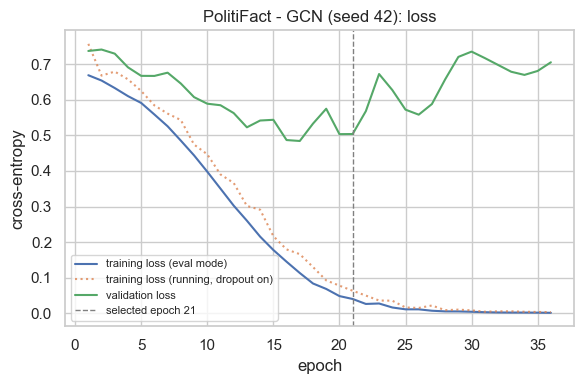

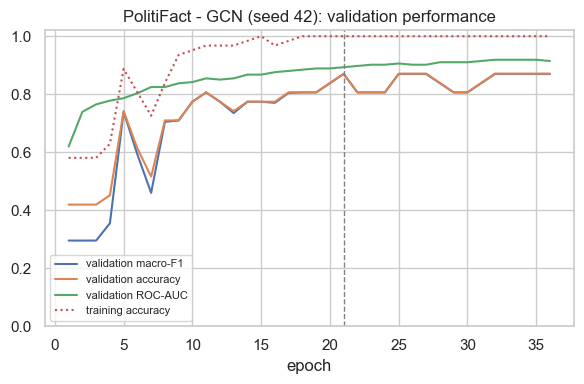

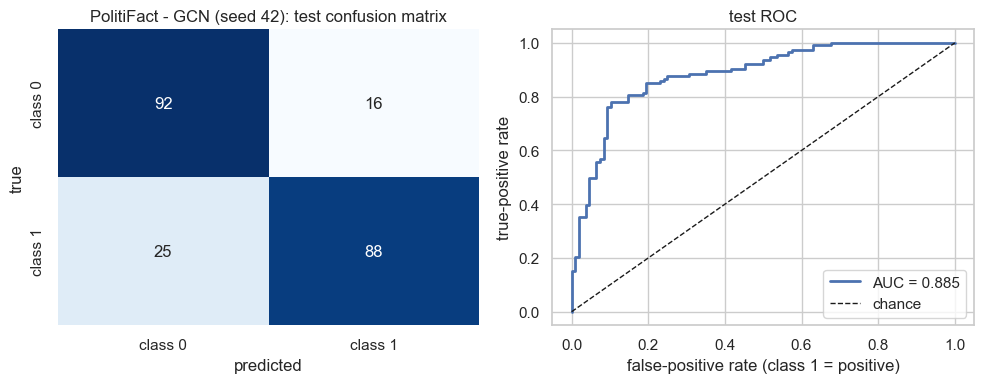

GCN        PolitiFact  seed 42 | best epoch  21/36 | test acc 0.814 macro-F1 0.814 | 13s


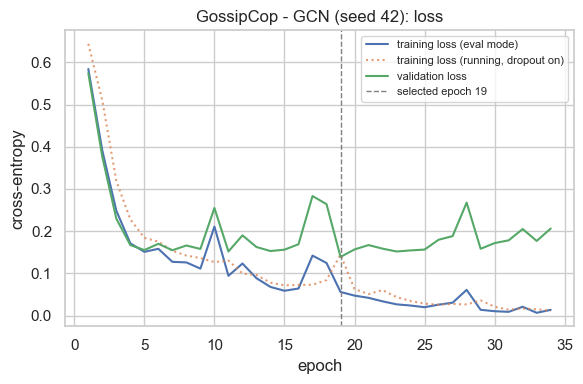

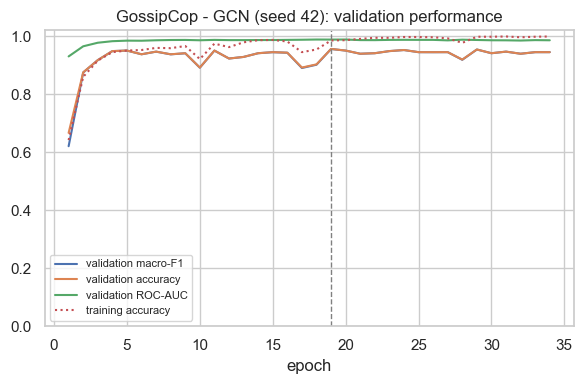

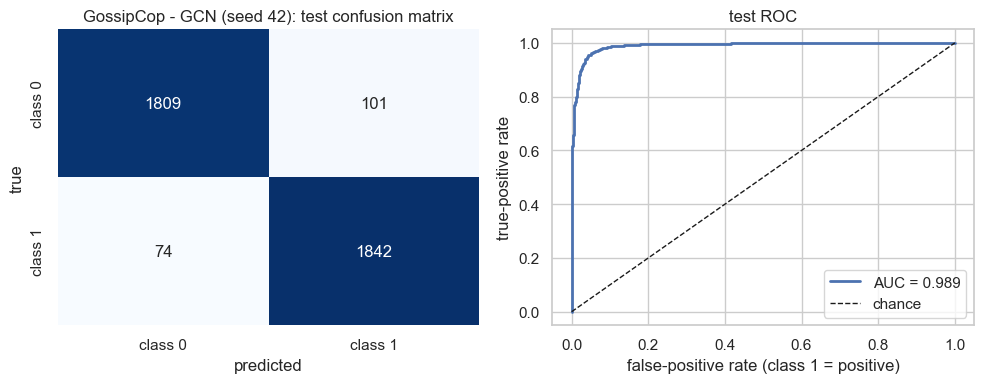

GCN        GossipCop   seed 42 | best epoch  19/34 | test acc 0.954 macro-F1 0.954 | 108s
GCN        PolitiFact  seed 43 | best epoch  24/39 | test acc 0.824 macro-F1 0.823 | 14s
GCN        GossipCop   seed 43 | best epoch  22/37 | test acc 0.950 macro-F1 0.950 | 119s
GCN        PolitiFact  seed 44 | best epoch  22/37 | test acc 0.824 macro-F1 0.823 | 13s
GCN        GossipCop   seed 44 | best epoch  35/50 | test acc 0.956 macro-F1 0.956 | 161s
GCN        PolitiFact  seed 45 | best epoch  31/46 | test acc 0.833 macro-F1 0.832 | 17s
GCN        GossipCop   seed 45 | best epoch   6/21 | test acc 0.941 macro-F1 0.941 | 67s
GCN        PolitiFact  seed 46 | best epoch  31/46 | test acc 0.828 macro-F1 0.828 | 17s
GCN        GossipCop   seed 46 | best epoch   9/24 | test acc 0.944 macro-F1 0.944 | 77s


accuracy         f1_macro         roc_auc        
               mean     std     mean     std    mean     std
dataset                                                     
GossipCop    0.9491  0.0063   0.9491  0.0063  0.9854  0.0038
PolitiFact   0.8244  0.0067   0.8242  0.0067  0.8882  0.0048

In [17]:
run_model("GCN")

### 6.2 GAT

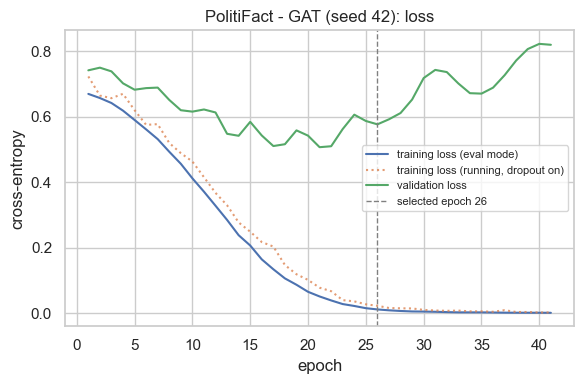

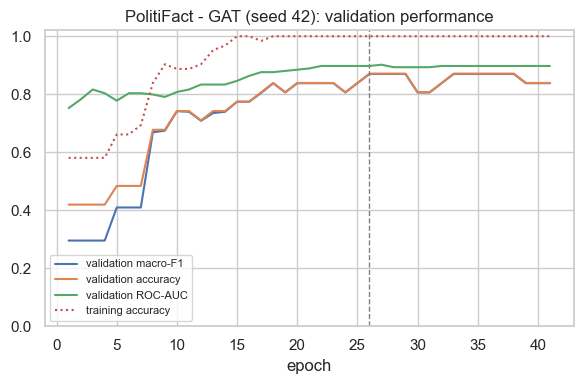

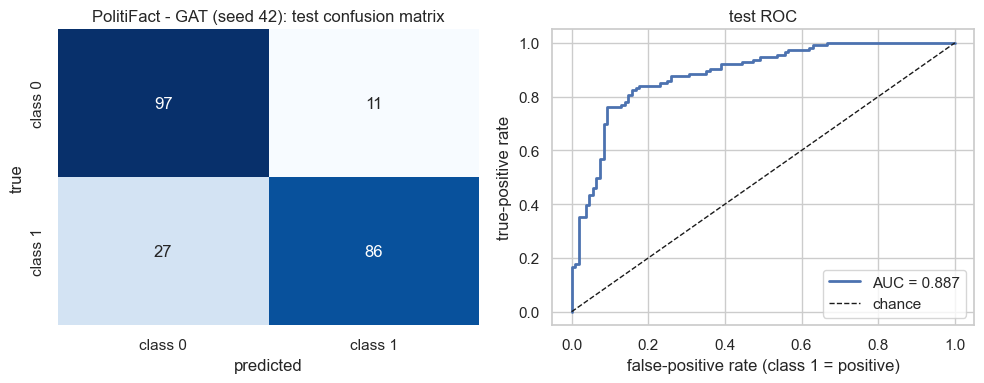

GAT        PolitiFact  seed 42 | best epoch  26/41 | test acc 0.828 macro-F1 0.828 | 16s


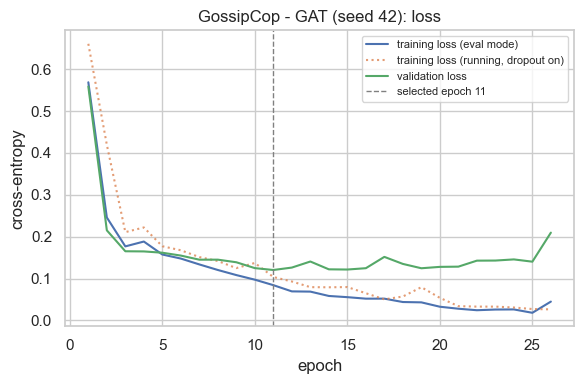

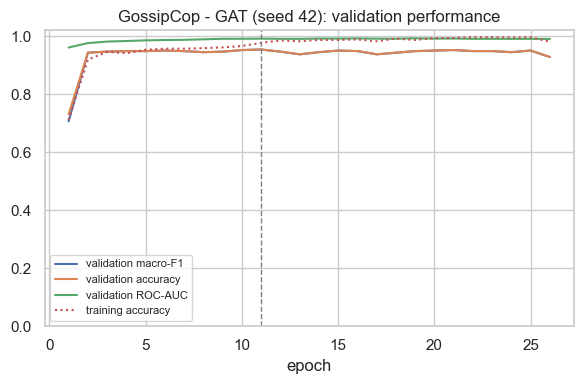

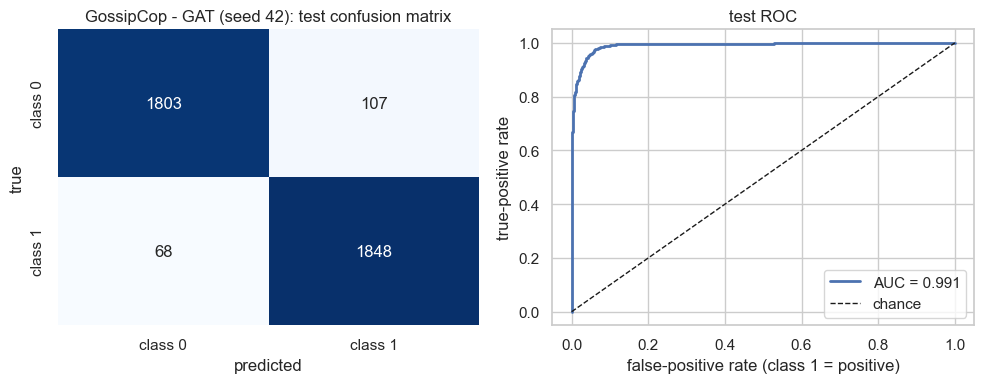

GAT        GossipCop   seed 42 | best epoch  11/26 | test acc 0.954 macro-F1 0.954 | 93s
GAT        PolitiFact  seed 43 | best epoch  20/35 | test acc 0.814 macro-F1 0.814 | 13s
GAT        GossipCop   seed 43 | best epoch  19/34 | test acc 0.967 macro-F1 0.967 | 121s
GAT        PolitiFact  seed 44 | best epoch  21/36 | test acc 0.814 macro-F1 0.814 | 14s
GAT        GossipCop   seed 44 | best epoch  21/36 | test acc 0.966 macro-F1 0.966 | 136s
GAT        PolitiFact  seed 45 | best epoch  27/42 | test acc 0.833 macro-F1 0.832 | 17s
GAT        GossipCop   seed 45 | best epoch  24/39 | test acc 0.961 macro-F1 0.961 | 138s
GAT        PolitiFact  seed 46 | best epoch  22/37 | test acc 0.824 macro-F1 0.823 | 14s
GAT        GossipCop   seed 46 | best epoch  45/60 | test acc 0.966 macro-F1 0.966 | 215s


accuracy         f1_macro         roc_auc        
               mean     std     mean     std    mean     std
dataset                                                     
GossipCop    0.9629  0.0054   0.9629  0.0054  0.9914  0.0010
PolitiFact   0.8226  0.0081   0.8224  0.0080  0.8811  0.0031

In [18]:
run_model("GAT")

### 6.3 GraphSAGE

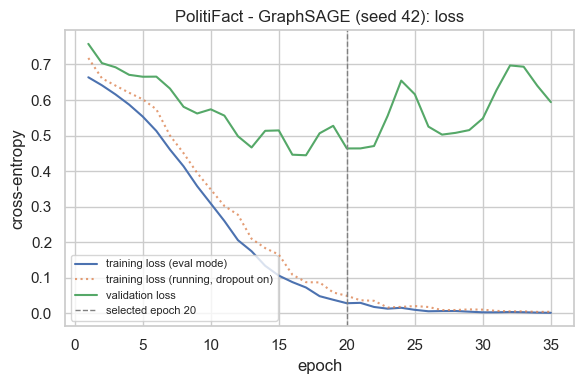

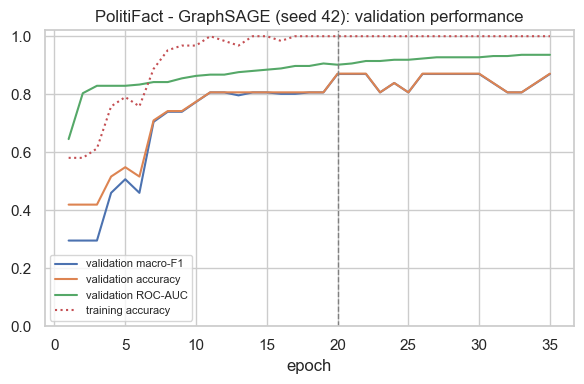

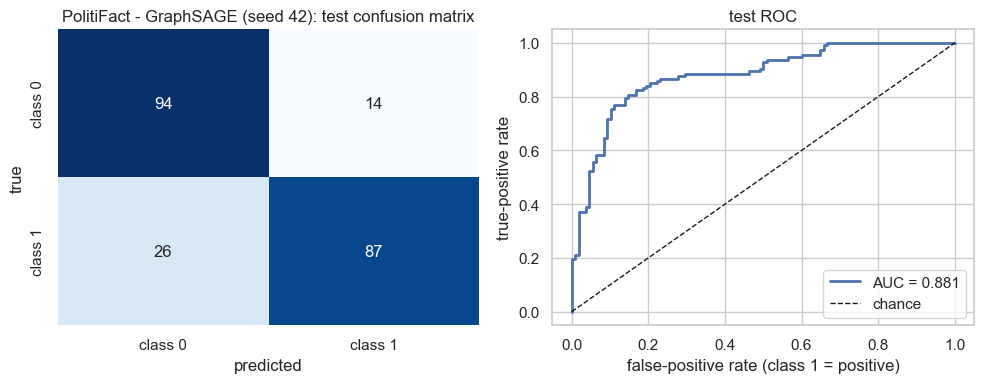

GraphSAGE  PolitiFact  seed 42 | best epoch  20/35 | test acc 0.819 macro-F1 0.819 | 18s


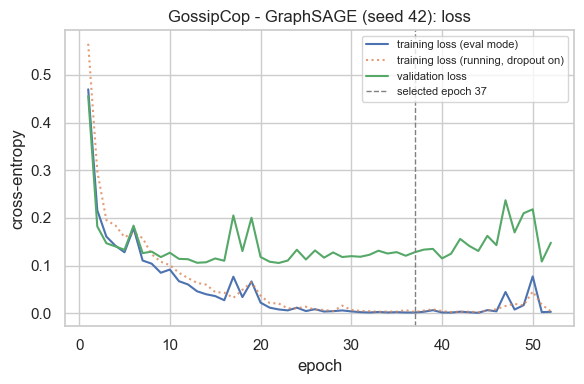

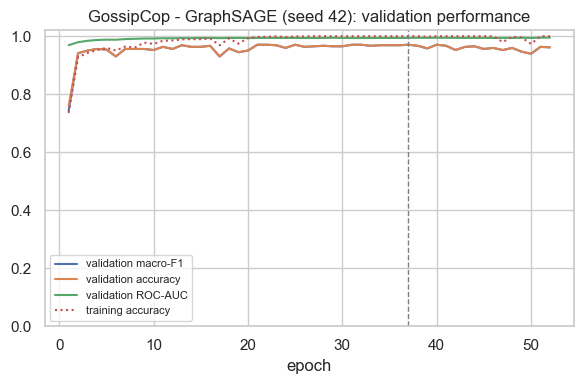

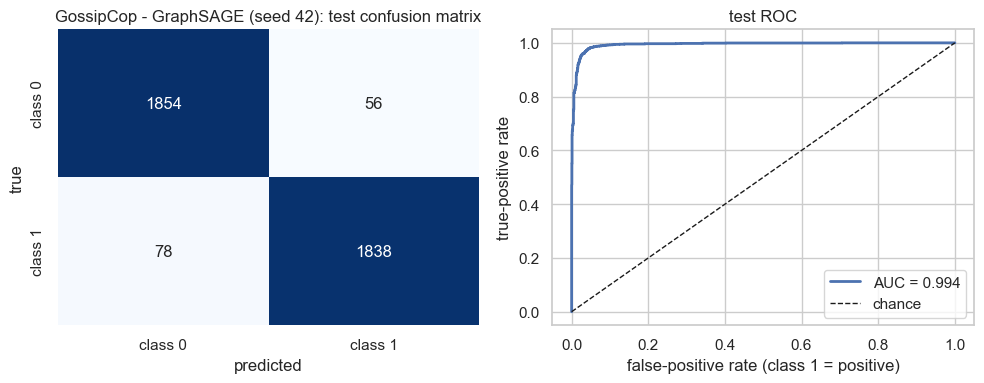

GraphSAGE  GossipCop   seed 42 | best epoch  37/52 | test acc 0.965 macro-F1 0.965 | 241s
GraphSAGE  PolitiFact  seed 43 | best epoch  26/41 | test acc 0.828 macro-F1 0.828 | 21s
GraphSAGE  GossipCop   seed 43 | best epoch  58/73 | test acc 0.968 macro-F1 0.968 | 341s
GraphSAGE  PolitiFact  seed 44 | best epoch  24/39 | test acc 0.810 macro-F1 0.809 | 20s
GraphSAGE  GossipCop   seed 44 | best epoch  29/44 | test acc 0.969 macro-F1 0.969 | 224s
GraphSAGE  PolitiFact  seed 45 | best epoch  21/36 | test acc 0.828 macro-F1 0.828 | 20s
GraphSAGE  GossipCop   seed 45 | best epoch  23/38 | test acc 0.967 macro-F1 0.967 | 194s
GraphSAGE  PolitiFact  seed 46 | best epoch  23/38 | test acc 0.828 macro-F1 0.828 | 20s
GraphSAGE  GossipCop   seed 46 | best epoch  20/35 | test acc 0.963 macro-F1 0.963 | 161s


accuracy         f1_macro         roc_auc        
               mean     std     mean     std    mean     std
dataset                                                     
GossipCop    0.9664  0.0022   0.9664  0.0022  0.9935  0.0004
PolitiFact   0.8226  0.0081   0.8221  0.0084  0.8853  0.0043

In [19]:
run_model("GraphSAGE")

In [20]:
logger.info("All runs finished.")

## 7 · Comparison

In [21]:
METRIC_COLS = {"accuracy": "Accuracy", "precision_macro": "Precision (macro)", "recall_macro": "Recall (macro)",
               "f1_macro": "Macro F1", "roc_auc": "ROC-AUC"}


def load_gnn_metrics():
    p = GNN_METRICS_DIR / "gnn_metrics.csv"
    if not p.is_file():
        raise FileNotFoundError("No GNN metrics found. Run section 6 first.")
    m = pd.read_csv(p)
    return m[m["setting"] == SETTING]


def load_run_metadata():
    rows = []
    for p in sorted(GNN_METRICS_DIR.glob("*_metadata.json")):
        d = json.loads(p.read_text(encoding="utf-8"))
        if d.get("setting") == SETTING:
            rows.append(d)
    return pd.DataFrame(rows)


def build_comparison(ds):
    m, meta = load_gnn_metrics(), load_run_metadata()
    m, meta = m[m["dataset_key"] == ds], meta[meta["dataset_key"] == ds]
    rows = []
    for model in GNN_MODELS:
        t = m[(m["model"] == model) & (m["split"] == "test")]
        v = m[(m["model"] == model) & (m["split"] == "val")]
        mt = meta[meta["model"] == model]
        if t.empty:
            continue
        row = {"Dataset": DATASET_TITLES[ds], "Model": model}
        row.update({pretty: t[c].mean() for c, pretty in METRIC_COLS.items()})
        row.update({"Accuracy std": t["accuracy"].std(), "Macro F1 std": t["f1_macro"].std(),
                    "Val macro-F1": v["f1_macro"].mean(),
                    "Layers": NUM_LAYERS, "Pooling": READOUT, "Root fusion": ROOT_FUSION, "seeds": int(t["seed"].nunique()),
                    "best epoch": mt["best_epoch"].mean(), "epochs run": mt["epochs_run"].mean(),
                    "train time (s)": mt["train_time_s"].mean(), "parameters": int(mt["n_params"].iloc[0]),
                    "peak GPU (MB)": pd.to_numeric(mt["peak_gpu_mb"], errors="coerce").mean(),
                    "CPU memory (MB)": mt["cpu_rss_mb"].mean(),
                    "train-val acc gap": (mt["train_acc_at_best"] - mt["val_acc_at_best"]).mean(),
                    "val-train loss gap": (mt["val_loss_at_best"] - mt["train_loss_at_best"]).mean(),
                    "test graphs": int(t["n"].iloc[0])})
        rows.append(row)
    return pd.DataFrame(rows)


def read_history(model, ds, seed):
    p = GNN_LOG_DIR / f"{run_tag(model, ds, seed)}_history.csv"
    return pd.read_csv(p) if p.is_file() else None


def read_predictions(model, ds, seed, split="test"):
    p = GNN_PRED_DIR / f"{run_tag(model, ds, seed)}_predictions.csv"
    if not p.is_file():
        return None
    d = pd.read_csv(p)
    return d[d["split"] == split]


def plot_comparison(ds, seed):
    title = DATASET_TITLES[ds]
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for model in GNN_MODELS:
        h = read_history(model, ds, seed)
        if h is None:
            continue
        axes[0].plot(h["epoch"], h["val_f1_macro"], label=model, color=MODEL_COLORS[model])
        axes[1].plot(h["epoch"], h["val_loss"], label=f"{model} (val)", color=MODEL_COLORS[model])
        axes[1].plot(h["epoch"], h["train_loss"], label=f"{model} (train)", color=MODEL_COLORS[model], ls=":")
    axes[0].set_title(f"{title}: validation macro-F1"); axes[0].set_xlabel("epoch"); axes[0].set_ylim(0, 1.02); axes[0].legend()
    axes[1].set_title(f"{title}: train (dotted) / validation loss"); axes[1].set_xlabel("epoch"); axes[1].legend(fontsize=8)
    plt.tight_layout(); save_figure(fig, GNN_FIG_DIR / f"comparison_{ds}_{SETTING}_validation_curves.png"); plt.show()
    fig, ax = plt.subplots(figsize=(5.5, 5))
    for model in GNN_MODELS:
        p = read_predictions(model, ds, seed)
        if p is None or p["y_true"].nunique() < 2:
            continue
        fpr, tpr, _ = roc_curve(p["y_true"], p["p_class1"])
        ax.plot(fpr, tpr, lw=2, color=MODEL_COLORS[model], label=f"{model} (AUC {roc_auc_score(p['y_true'], p['p_class1']):.3f})")
    ax.plot([0, 1], [0, 1], "k--", lw=1)
    ax.set_xlabel("false-positive rate"); ax.set_ylabel("true-positive rate"); ax.set_title(f"{title}: test ROC"); ax.legend(loc="lower right")
    plt.tight_layout(); save_figure(fig, GNN_FIG_DIR / f"comparison_{ds}_{SETTING}_roc.png"); plt.show()
    fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
    for ax, model in zip(axes, GNN_MODELS):
        p = read_predictions(model, ds, seed)
        if p is None:
            ax.axis("off"); continue
        plot_confusion_ax(ax, p["y_true"], p["y_pred"], model)
    fig.suptitle(f"{title}: test confusion matrices (seed {seed})"); plt.tight_layout()
    save_figure(fig, GNN_FIG_DIR / f"comparison_{ds}_{SETTING}_confusion_matrices.png"); plt.show()


def plot_metric_bars(table, ds):
    cols = list(METRIC_COLS.values())
    long = table.melt(id_vars=["Model"], value_vars=cols, var_name="metric", value_name="value")
    fig, ax = plt.subplots(figsize=(10, 4))
    sns.barplot(data=long, x="metric", y="value", hue="Model", hue_order=[m for m in GNN_MODELS if m in set(table["Model"])], palette=MODEL_COLORS, ax=ax)
    for cont in ax.containers:
        ax.bar_label(cont, fmt="%.2f", fontsize=8, padding=2)
    ax.set_ylim(0, 1.08); ax.set_xlabel(""); ax.set_ylabel("test score"); ax.set_title(f"{DATASET_TITLES[ds]}: test metrics (mean over seeds)")
    plt.tight_layout(); save_figure(fig, GNN_FIG_DIR / f"comparison_{ds}_{SETTING}_metric_bars.png"); plt.show()


COMPARISON = {}


def show_dataset_comparison(ds):
    table = build_comparison(ds)
    COMPARISON[ds] = table
    save_dataframe(table, GNN_METRICS_DIR / f"gnn_comparison_{ds}_{SETTING}.csv")
    display(table.round(4))
    plot_comparison(ds, SEEDS[0])
    plot_metric_bars(table, ds)

### 7.1 PolitiFact

,Dataset,Model,Accuracy,Precision (macro),Recall (macro),Macro F1,ROC-AUC,Accuracy std,Macro F1 std,Val macro-F1,Layers,Pooling,Root fusion,seeds,best epoch,epochs run,train time (s),parameters,peak GPU (MB),CPU memory (MB),train-val acc gap,val-train loss gap,test graphs
0,PolitiFact,GCN,0.8244,0.8283,0.8256,0.8242,0.8882,0.0067,0.0067,0.8697,1,max,True,5,25.8,40.8,14.618,230018,NaN,1798.02,0.1290,0.5509,221
1,PolitiFact,GAT,0.8226,0.8267,0.8238,0.8224,0.8811,0.0081,0.0080,0.8697,1,max,True,5,23.2,38.2,14.800,230274,NaN,1803.22,0.1290,0.5112,221
2,PolitiFact,GraphSAGE,0.8226,0.8292,0.8242,0.8221,0.8853,0.0081,0.0084,0.8764,1,max,True,5,22.8,37.8,19.852,328322,NaN,1810.00,0.1226,0.4908,221


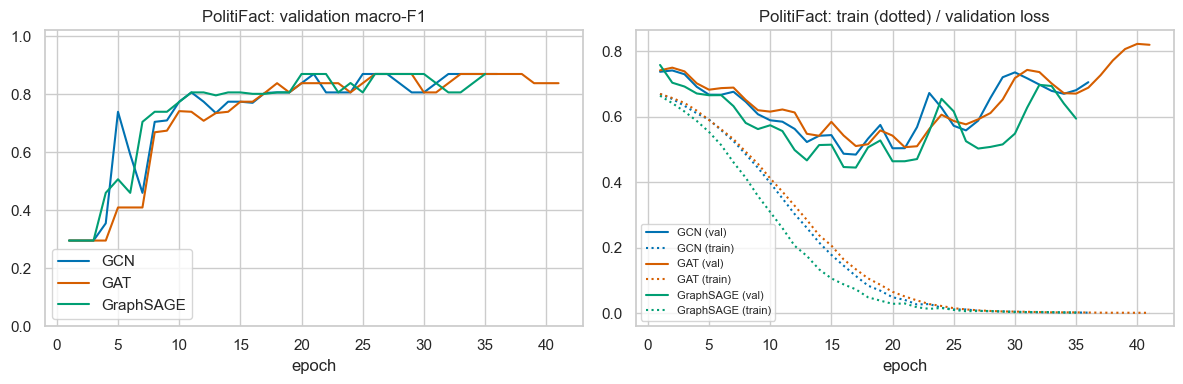

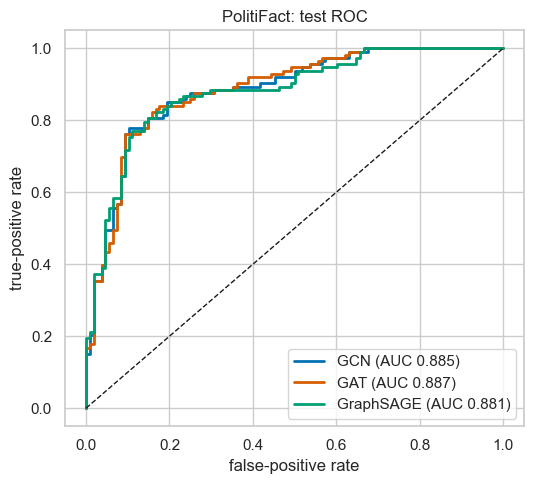

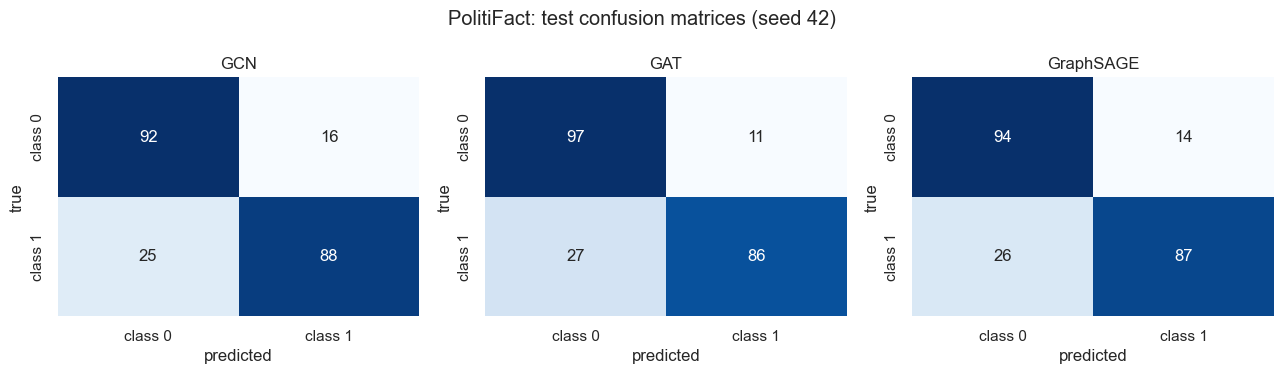

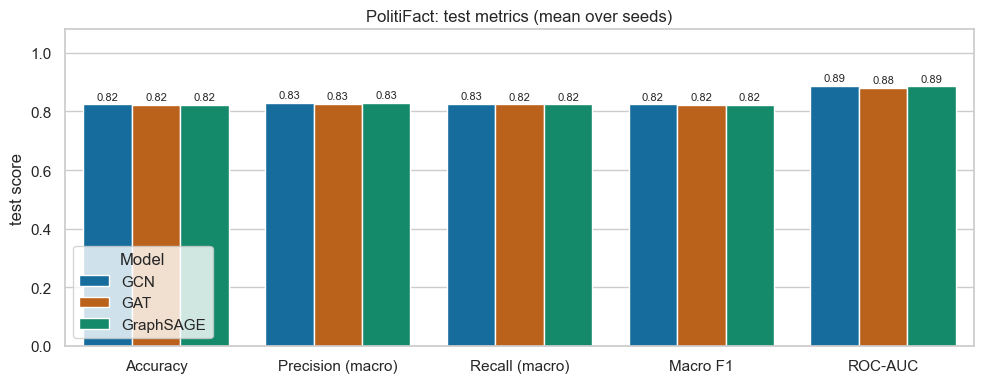

In [22]:
show_dataset_comparison("politifact")

### 7.2 GossipCop

,Dataset,Model,Accuracy,Precision (macro),Recall (macro),Macro F1,ROC-AUC,Accuracy std,Macro F1 std,Val macro-F1,Layers,Pooling,Root fusion,seeds,best epoch,epochs run,train time (s),parameters,peak GPU (MB),CPU memory (MB),train-val acc gap,val-train loss gap,test graphs
0,GossipCop,GCN,0.9491,0.9491,0.9491,0.9491,0.9854,0.0063,0.0063,0.9531,1,max,True,5,18.2,33.2,106.376,230018,NaN,1792.32,0.0234,0.0704,3826
1,GossipCop,GAT,0.9629,0.9630,0.9629,0.9629,0.9914,0.0054,0.0054,0.9600,1,max,True,5,24.0,39.0,140.618,230274,NaN,1790.62,0.0319,0.1002,3826
2,GossipCop,GraphSAGE,0.9664,0.9665,0.9664,0.9664,0.9935,0.0022,0.0022,0.9703,1,max,True,5,33.4,48.4,232.324,328322,NaN,1784.48,0.0289,0.1187,3826


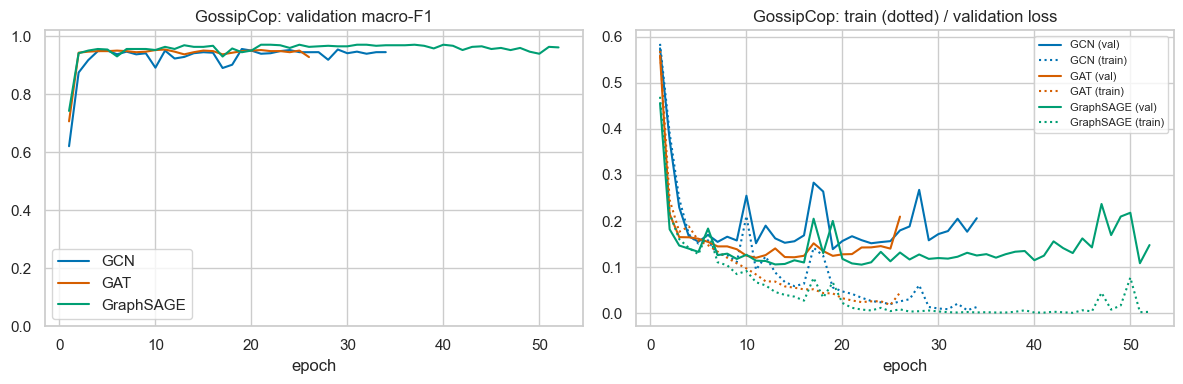

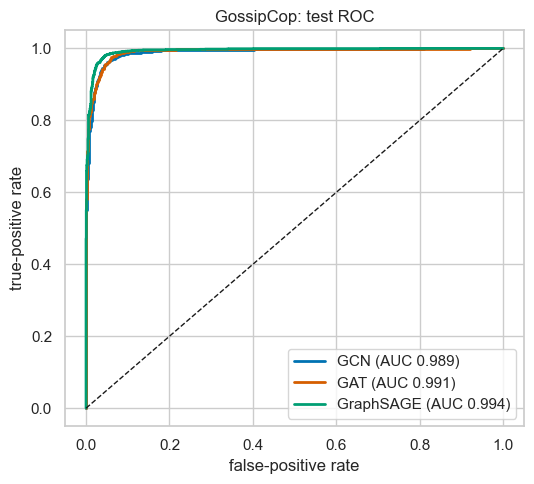

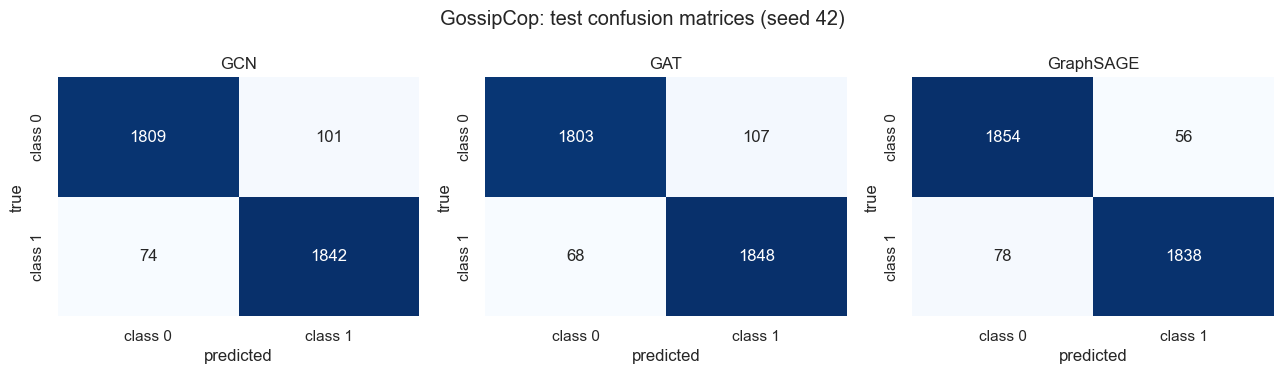

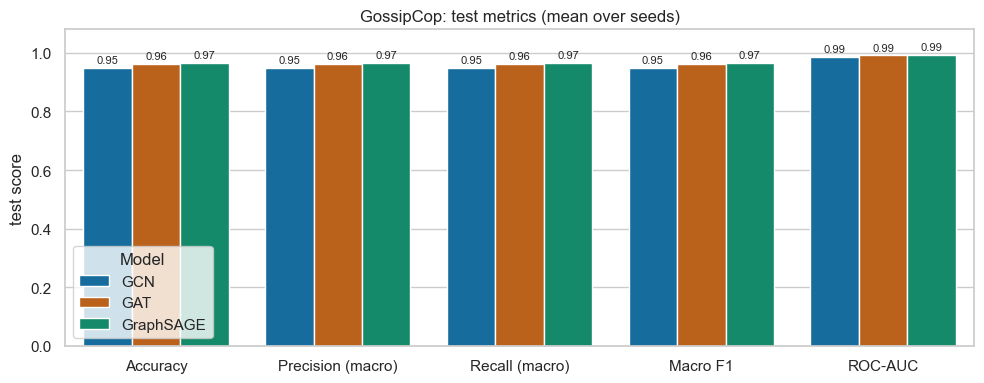

In [23]:
show_dataset_comparison("gossipcop")

### 7.3 Baselines and GNNs together (needs notebook 02 results)

,Dataset,Model,Accuracy,Precision (macro),Recall (macro),Macro F1,ROC-AUC,seeds,test graphs,Family
0,GossipCop,Text-only MLP,0.7404,0.7454,0.7405,0.7391,0.8106,5,3826,baseline (notebook 02)
1,GossipCop,Propagation-only RF,0.8152,0.8160,0.8152,0.8151,0.8881,5,3826,baseline (notebook 02)
2,GossipCop,GCN,0.9491,0.9491,0.9491,0.9491,0.9854,5,3826,GNN (notebook 03)
3,GossipCop,GAT,0.9629,0.9630,0.9629,0.9629,0.9914,5,3826,GNN (notebook 03)
4,GossipCop,GraphSAGE,0.9664,0.9665,0.9664,0.9664,0.9935,5,3826,GNN (notebook 03)
5,PolitiFact,Text-only MLP,0.8127,0.8220,0.8146,0.8118,0.8628,5,221,baseline (notebook 02)
6,PolitiFact,Propagation-only RF,0.5195,0.5369,0.5255,0.4856,0.5590,5,221,baseline (notebook 02)
7,PolitiFact,GCN,0.8244,0.8283,0.8256,0.8242,0.8882,5,221,GNN (notebook 03)
8,PolitiFact,GAT,0.8226,0.8267,0.8238,0.8224,0.8811,5,221,GNN (notebook 03)
9,PolitiFact,GraphSAGE,0.8226,0.8292,0.8242,0.8221,0.8853,5,221,GNN (notebook 03)


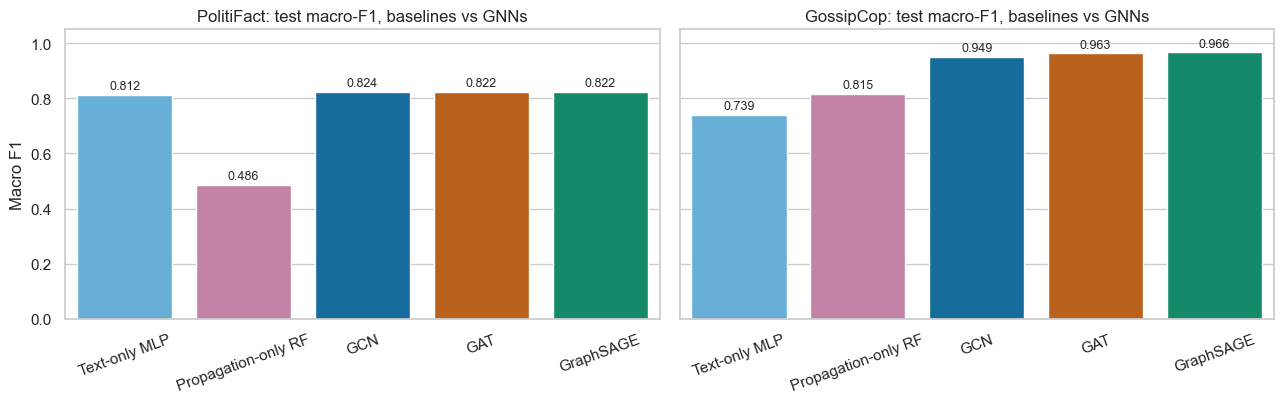

In [24]:
BASELINE_PATH = METRICS_DIR / "baselines" / "baseline_comparison.csv"
COMBINED = None
if not BASELINE_PATH.is_file():
    print(f"Baseline results not found ({BASELINE_PATH.relative_to(PROJECT_ROOT)}): run notebook 02 first if you want this comparison. "
          "The GNN comparison above is complete without it.")
else:
    base = pd.read_csv(BASELINE_PATH)
    keep = ["Dataset", "Model"] + list(METRIC_COLS.values()) + ["seeds", "test graphs"]
    parts = [base[[c for c in keep if c in base.columns]].assign(Family="baseline (notebook 02)")]
    for ds in DATASETS:
        if ds in COMPARISON and not COMPARISON[ds].empty:
            parts.append(COMPARISON[ds][[c for c in keep if c in COMPARISON[ds].columns]].assign(Family="GNN (notebook 03)"))
    COMBINED = pd.concat(parts, ignore_index=True)
    order = ["Text-only MLP", "Propagation-only RF", "GCN", "GAT", "GraphSAGE"]
    COMBINED["_o"] = COMBINED["Model"].map({m: i for i, m in enumerate(order)})
    COMBINED = COMBINED.sort_values(["Dataset", "_o"]).drop(columns="_o").reset_index(drop=True)
    save_dataframe(COMBINED, GNN_METRICS_DIR / f"baselines_and_gnns_combined_{SETTING}.csv")
    display(COMBINED.round(4))

    for ds in DATASETS:
        sub = COMBINED[COMBINED["Dataset"] == DATASET_TITLES[ds]]
        sizes = sub["test graphs"].dropna().unique()
        if len(sizes) > 1:
            print(f"WARNING [{DATASET_TITLES[ds]}]: differing numbers of test graphs {sizes} - the splits do not match; do not compare directly.")
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
    pal = {"Text-only MLP": "#56B4E9", "Propagation-only RF": "#CC79A7", **MODEL_COLORS}
    for ax, ds in zip(axes, DATASETS):
        sub = COMBINED[COMBINED["Dataset"] == DATASET_TITLES[ds]]
        sns.barplot(data=sub, x="Model", y="Macro F1", hue="Model", palette=pal, legend=False, ax=ax)
        for cont in ax.containers:
            ax.bar_label(cont, fmt="%.3f", fontsize=9, padding=2)
        ax.set_ylim(0, 1.05); ax.set_title(f"{DATASET_TITLES[ds]}: test macro-F1, baselines vs GNNs"); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=20)
    plt.tight_layout(); save_figure(fig, GNN_FIG_DIR / f"comparison_baselines_vs_gnns_macro_f1_{SETTING}.png"); plt.show()

## 8 · Best model by validation and notes

In [25]:
lines, best_val = [], {}
for ds in DATASETS:
    t = COMPARISON.get(ds)
    if t is None or t.empty:
        continue
    T = DATASET_TITLES[ds]
    top_test = t.sort_values("Macro F1", ascending=False).iloc[0]
    top_val = t.sort_values("Val macro-F1", ascending=False).iloc[0]
    best_val[ds] = top_val["Model"]
    lines.append(f"[{T}] best test macro-F1: {top_test['Model']} ({top_test['Macro F1']:.3f}); best validation macro-F1: {top_val['Model']} ({top_val['Val macro-F1']:.3f})")
    lines.append(f"[{T}] test macro-F1 mean ± std over {int(t['seeds'].min())} seeds: " + ", ".join(f"{r['Model']} {r['Macro F1']:.3f} ± {r['Macro F1 std']:.3f}" for _, r in t.iterrows()))
    lines.append(f"[{T}] test graphs: {int(t['test graphs'].iloc[0])} (one graph = {100 / t['test graphs'].iloc[0]:.2f} accuracy points)")
    lines.append(f"[{T}] training time (s): " + ", ".join(f"{r['Model']} {r['train time (s)']:.0f}" for _, r in t.iterrows()))
print("\n".join("- " + l for l in lines))

if best_val:
    save_json({"selection_rule": "highest mean validation macro-F1 (test set not used)", "setting": SETTING, "best_gnn_by_dataset": best_val},
              GNN_METRICS_DIR / "best_gnn_by_validation.json")
    save_json({"setting": SETTING, "edge_mode": EDGE_MODE, "readout": READOUT, "num_layers": NUM_LAYERS, "root_fusion": ROOT_FUSION,
               "cfg": CFG, "batch_size": BATCH_SIZE, "eval_batch_size": EVAL_BATCH_SIZE, "seeds": SEEDS}, GNN_METRICS_DIR / "gnn_config.json")

- [PolitiFact] best test macro-F1: GCN (0.824); best validation macro-F1: GraphSAGE (0.876)
- [PolitiFact] test macro-F1 mean ± std over 5 seeds: GCN 0.824 ± 0.007, GAT 0.822 ± 0.008, GraphSAGE 0.822 ± 0.008
- [PolitiFact] test graphs: 221 (one graph = 0.45 accuracy points)
- [PolitiFact] training time (s): GCN 15, GAT 15, GraphSAGE 20
- [GossipCop] best test macro-F1: GraphSAGE (0.966); best validation macro-F1: GraphSAGE (0.970)
- [GossipCop] test macro-F1 mean ± std over 5 seeds: GCN 0.949 ± 0.006, GAT 0.963 ± 0.005, GraphSAGE 0.966 ± 0.002
- [GossipCop] test graphs: 3826 (one graph = 0.03 accuracy points)
- [GossipCop] training time (s): GCN 106, GAT 141, GraphSAGE 232


Notes:
- A difference of a few points on the small PolitiFact test split is within noise; compare means and standard deviations over the five seeds.
- Edges are used as stored (parent to child), so the root receives no messages from users. Root fusion keeps its own vector available to the classifier. The official example makes edges undirected: set `EDGE_MODE = "undirected"` for that sensitivity run.
- Hyper-parameters are the same for every model and were not tuned per model.
- The fake/real label meaning is unverified, so classes are reported as class 0 / class 1.

## 9 · Other settings run so far

In [26]:
allm = pd.read_csv(GNN_METRICS_DIR / "gnn_metrics.csv")
allm = allm[(allm["split"] == "test") & allm["setting"].notna()]
tab = allm.groupby(["setting", "dataset", "model"])["f1_macro"].agg(["mean", "std", "count"]).round(4).reset_index()
tab = tab.rename(columns={"mean": "macro-F1 mean", "std": "macro-F1 std", "count": "runs"})
display(tab)
if allm["setting"].nunique() == 1:
    print("Only one setting has been run. Change READOUT, NUM_LAYERS or ROOT_FUSION in section 2 and rerun sections 2 to 7 to compare.")
save_dataframe(tab, GNN_METRICS_DIR / "settings_comparison.csv")

,setting,dataset,model,macro-F1 mean,macro-F1 std,runs
0,L1_max_root_as_stored,GossipCop,GAT,0.9629,0.0054,5
1,L1_max_root_as_stored,GossipCop,GCN,0.9491,0.0063,5
2,L1_max_root_as_stored,GossipCop,GraphSAGE,0.9664,0.0022,5
3,L1_max_root_as_stored,PolitiFact,GAT,0.8224,0.0080,5
4,L1_max_root_as_stored,PolitiFact,GCN,0.8242,0.0067,5
5,L1_max_root_as_stored,PolitiFact,GraphSAGE,0.8221,0.0084,5


Only one setting has been run. Change READOUT, NUM_LAYERS or ROOT_FUSION in section 2 and rerun sections 2 to 7 to compare.


WindowsPath('C:/Users/shara/FakeNews-detection-GNN/results/metrics/gnn/settings_comparison.csv')

## 10 · Batch size and memory

In [27]:
def time_one_epoch(model_name, ds, batch_size):
    set_seed(SEEDS[0])
    model = MODEL_BUILDERS[model_name](EXPECTED_FEATURE_DIM).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=CFG["lr"])
    loader = DataLoader(GRAPHS[ds]["train"], batch_size=batch_size, shuffle=True)
    if DEVICE.type == "cuda":
        torch.cuda.reset_peak_memory_stats()
    model.train()
    t0 = time.perf_counter()
    for batch in loader:
        batch = batch.to(DEVICE)
        opt.zero_grad(set_to_none=True)
        loss = F.cross_entropy(model(batch.x, batch.edge_index, batch.batch, batch.ptr), batch.y)
        loss.backward()
        opt.step()
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    return {"dataset": DATASET_TITLES[ds], "model": model_name, "batch_size": batch_size, "epoch_seconds": round(time.perf_counter() - t0, 2),
            "peak_gpu_mb": round(torch.cuda.max_memory_allocated() / 1e6, 1) if DEVICE.type == "cuda" else None, "cpu_memory_mb": round(rss_mb(), 1)}


SCALE = pd.DataFrame([time_one_epoch("GraphSAGE", ds, bs) for ds in DATASETS for bs in (16, 32, 64, 128)])
save_dataframe(SCALE, GNN_METRICS_DIR / "batch_size_timing.csv")
display(SCALE)

,dataset,model,batch_size,epoch_seconds,peak_gpu_mb,cpu_memory_mb
0,PolitiFact,GraphSAGE,16,0.34,None,1579.4
1,PolitiFact,GraphSAGE,32,0.25,None,1568.2
2,PolitiFact,GraphSAGE,64,0.21,None,1559.1
3,PolitiFact,GraphSAGE,128,0.18,None,1559.3
4,GossipCop,GraphSAGE,16,3.53,None,1544.4
5,GossipCop,GraphSAGE,32,3.13,None,1555.2
6,GossipCop,GraphSAGE,64,2.67,None,1566.0
7,GossipCop,GraphSAGE,128,2.23,None,1568.6


## 11 · Saved files

In [28]:
logger.info("Notebook 03 finished.")
inventory = pd.DataFrame(SAVED_ARTIFACTS)
display(inventory)
print(f"\nFiles written during this execution: {len(inventory)} | log: {LOG_PATH.relative_to(PROJECT_ROOT)}")

,kind,path,size_kB
0,csv,results\metrics\gnn\data_cost.csv,0.1
1,checkpoint,results\checkpoints\gnn\gcn_politifact_seed42_...,902.8
2,csv,results\logs\gnn\gcn_politifact_seed42_L1_max_...,5.3
3,csv,results\metrics\gnn\predictions\gcn_politifact...,6.1
4,csv,results\metrics\gnn\gnn_metrics.csv,3.9
...,...,...,...
180,figure,results\figures\gnn\comparison_baselines_vs_gn...,56.5
181,json,results\metrics\gnn\best_gnn_by_validation.json,0.2
182,json,results\metrics\gnn\gnn_config.json,0.5
183,csv,results\metrics\gnn\settings_comparison.csv,0.4



Files written during this execution: 185 | log: results\logs\gnn\gnn_comparison_20261108_132144.log
